# Case study 1: vibration of a 3-DOF system

This notebook reproduces the first case study of the paper with the library. The benchmark is a mass-spring-damper
chain with three degrees of freedom (3-DOF), excited by an impulse at each mass. The displacements and the
accelerations of the three masses are corrupted with noise, and TWN2N recovers them from the noisy signals alone.

The notebook runs one trial step by step (about two minutes of training on a laptop). It then explains how the
paper repeats this trial and places one example trial of each condition next to the values reported in the paper.

In [1]:
import os
import sys

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")     # quieter TensorFlow
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")    # these small networks train faster on the CPU
sys.path.insert(0, os.path.abspath(".."))              # use the library from this repository

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import figstyle
import twn2n

figstyle.apply()

sys.path.insert(0, os.path.abspath("../paper"))        # settings of the paper (seeds and noise realizations)
import cases
from twn2n import benchmarks, filters, modal

## 1. Benchmark and noise

Three masses of 3 kg are connected by four springs. The damping is proportional, and the natural frequencies and
damping ratios are printed below. Each record lasts 3 s at 1024 Hz. White Gaussian noise is added to every
channel at an input signal-to-noise ratio (SNR) of 15 dB.

`cases.paper_rng` returns the random generator of the paper, so this trial uses the noise realization of trial 0
of the paper.

In [2]:
system = benchmarks.three_dof_system()
t, clean = benchmarks.three_dof_impulse_responses(system)
noisy = twn2n.add_noise(clean, "white", snr_db=15.0, rng=cases.paper_rng("white", 15.0, trial=0))

print("natural frequencies (Hz):", np.round(system.fn, 2))
print("damping ratios:          ", np.round(system.zeta, 4))
print(f"{len(clean)} records of shape {clean[0].shape}; channels {benchmarks.THREE_DOF_CHANNELS}")
print(f"input SNR of the displacements: {twn2n.snr_db(clean, noisy, channels=[0, 1, 2]):.2f} dB")

natural frequencies (Hz): [ 40.15 120.1  239.91]
damping ratios:           [0.01   0.0072 0.01  ]
3 records of shape (3072, 6); channels ('x1', 'x2', 'x3', 'a1', 'a2', 'a3')
input SNR of the displacements: 15.00 dB


## 2. Denoising with TWN2N

The settings are those of the paper: two neighbors on each side of the masked instant (`p = 2`, which gives
24 inputs for the six channels) and a bottleneck of four units (`r = 4`). The three records are given
together and a single network is trained.

In [3]:
model = twn2n.TWN2N(p=2, r=4, seed=cases.training_seed(0))
denoised = model.fit_denoise(noisy)

print(f"{model.n_parameters_} parameters | {model.epochs_run_} epochs (best: {model.best_epoch_}) | "
      f"{model.training_time_s_ / 60:.1f} min")
print(f"output SNR of the displacements: {twn2n.snr_db(clean, denoised, channels=[0, 1, 2]):.2f} dB")

17218 parameters | 211 epochs (best: 111) | 1.3 min
output SNR of the displacements: 21.41 dB


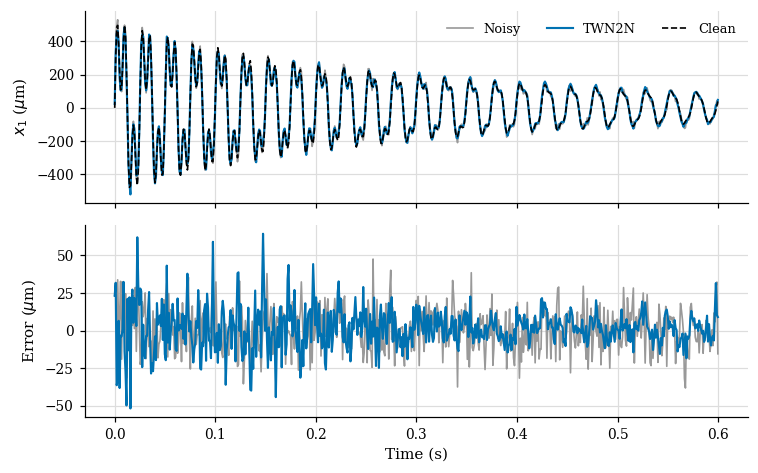

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(7.0, 4.4), sharex=True)
window = t < 0.6
record, channel = 0, 0                      # impulse at mass 1, displacement of mass 1
figstyle.line(axes[0], t[window], 1e6 * noisy[record][window, channel], "noisy")
figstyle.line(axes[0], t[window], 1e6 * denoised[record][window, channel], "twn2n", linewidth=1.4)
figstyle.line(axes[0], t[window], 1e6 * clean[record][window, channel], "clean")
axes[0].set_ylabel("$x_1$ ($\\mu$m)")
axes[0].legend(ncol=3, loc="upper right")
figstyle.line(axes[1], t[window], 1e6 * (noisy[record][window, channel] - clean[record][window, channel]), "noisy")
figstyle.line(axes[1], t[window], 1e6 * (denoised[record][window, channel] - clean[record][window, channel]), "twn2n",
              linewidth=1.4)
axes[1].set_ylabel("Error ($\\mu$m)")
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.savefig("figures/vibration_trial.png", bbox_inches="tight")
plt.show()

## 3. Comparison with classical filters

The paper compares TWN2N with three filters applied to the same noisy records:

* a zero-phase Butterworth low-pass filter of fourth order, with the cutoff fixed at 1.05 times the third natural
  frequency $f_3$, which requires knowing the band of the structure;
* the Savitzky-Golay filter, with a window of five samples and a polynomial of third order;
* the VisuShrink wavelet threshold, tuned with the exact noise level, which is unavailable in practice.

The gain is also computed inside the structural band (0 to 1.25 $f_3$), most of which lies below the cutoff of the
low-pass filter.

In [5]:
f3 = system.fn[2]
noise_std = np.std(np.vstack(noisy)[:, :3] - np.vstack(clean)[:, :3])
estimates = {
    "twn2n": denoised,
    "lowpass": filters.lowpass(noisy, cutoff_hz=1.05 * f3, fs=system.fs),
    "savgol": filters.savitzky_golay(noisy, window=5, polyorder=3),
    "visushrink": filters.visushrink(noisy, sigma=noise_std),
}
band = (0.0, 1.25 * f3)
inband_input = twn2n.band_snr_db(clean, noisy, band, system.fs, channels=[0, 1, 2])
rows = []
for name, estimate in estimates.items():
    rows.append({"method": figstyle.LABELS[name],
                 "gain (dB)": twn2n.snr_gain_db(clean, noisy, estimate, channels=[0, 1, 2]),
                 "gain inside the band (dB)": twn2n.band_snr_db(clean, estimate, band, system.fs, channels=[0, 1, 2]) - inband_input})
print(pd.DataFrame(rows).round(2).to_string(index=False))

        method  gain (dB)  gain inside the band (dB)
         TWN2N       6.41                       6.18
      Low-pass       3.22                       1.03
Savitzky-Golay       3.00                       1.02
    VisuShrink      -0.45                      -2.29


## 4. Effect on the identified modal parameters

Noise degrades the quantities derived from the signals. The Ibrahim Time Domain (ITD) method identifies the
natural frequencies and the damping ratios from the displacements of the first record. The damping ratio of the
third mode, the weakest in the response, is the most affected by the noise.

In [6]:
rows = []
for name, signals in (("Clean", clean), ("Noisy", noisy), ("TWN2N", denoised)):
    modes = modal.identify_modes(signals[0][:, :3], system.fs, delay=1, order=20)
    for match in modal.match_modes(modes, system.wn, system.zeta):
        rows.append({"signal": name, "mode": match["mode"], "frequency (Hz)": match["fn"], "damping ratio": match["zeta"]})
identified = pd.DataFrame(rows).pivot(index="mode", columns="signal", values="damping ratio")[["Clean", "Noisy", "TWN2N"]]
identified.insert(0, "Reference", system.zeta)
print("Damping ratios")
print(identified.round(4))

Damping ratios
signal  Reference   Clean   Noisy   TWN2N
mode                                     
1          0.0100  0.0100  0.0106  0.0098
2          0.0072  0.0072  0.0084  0.0073
3          0.0100  0.0100  0.0742  0.0101


## 5. The study of the paper

A single trial depends on the noise realization and on the initial weights of the network. For this reason the
paper repeats each condition thirty times, with a different noise realization and a different training seed in
each trial, and reports the mean and the standard deviation. The conditions are white noise at six input SNRs,
from 25 to 5 dB, and pink noise, brown noise, and quantization at 15 dB.

The values of the paper are stored in `paper/reference/vibration_trials.csv`, one row per trial. As examples,
`paper/results/vibration_trials.csv` stores one trial of each condition run with this library. The example stored
for white noise at 15 dB is the trial of this notebook, run with another version of TensorFlow; the two outputs
differ because the initial weights depend on the software version. The cells below
place these examples next to the statistics of the paper. Any other trial, or the thirty trials of a condition,
can be run with `paper/run.py`:

```bash
python paper/run.py vibration --noise white --snr 15 --trials 0
python paper/run.py vibration --study all --trials 0-29 --workers 6
```

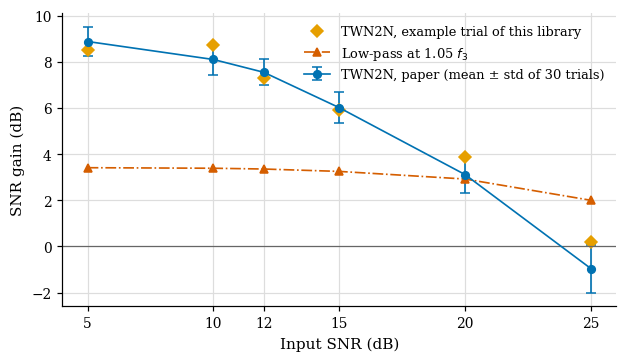

In [7]:
library = pd.read_csv("../paper/results/vibration_trials.csv")
paper = pd.read_csv("../paper/reference/vibration_trials.csv")
for frame in (library, paper):
    frame["twn2n_gain"] = frame.twn2n_snr - frame.noisy_snr
    frame["lowpass_gain"] = frame.lowpass_snr - frame.noisy_snr

white_paper = paper[paper.noise == "white"].groupby("snr_db")
white_library = library[library.noise == "white"].sort_values("snr_db")
snr = white_paper.twn2n_gain.mean().index.values
fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.errorbar(snr, white_paper.twn2n_gain.mean(), yerr=white_paper.twn2n_gain.std(), color=figstyle.COLORS["twn2n"],
            marker="o", markersize=5, capsize=3, label="TWN2N, paper (mean ± std of 30 trials)")
ax.plot(white_library.snr_db, white_library.twn2n_gain, color=figstyle.COLORS["paper"], marker="D", markersize=6,
        linestyle="none", label="TWN2N, example trial of this library")
ax.plot(snr, white_paper.lowpass_gain.mean(), color=figstyle.COLORS["lowpass"], marker="^", markersize=5,
        linestyle=figstyle.STYLES["lowpass"], label="Low-pass at 1.05 $f_3$")
ax.axhline(0, color="#666666", linewidth=0.8)
ax.set_xlabel("Input SNR (dB)")
ax.set_ylabel("SNR gain (dB)")
ax.set_xticks(snr)
ax.legend()
plt.tight_layout()
plt.savefig("figures/vibration_gain_vs_snr.png", bbox_inches="tight")
plt.show()

In [8]:
order = [("white", s) for s in (25.0, 20.0, 15.0, 12.0, 10.0, 5.0)] + [(k, 15.0) for k in ("pink", "brown", "quantization")]
grouped = paper.groupby(["noise", "snr_db"])
comparison = pd.DataFrame({
    "input": grouped.noisy_snr.mean(),
    "paper mean": grouped.twn2n_snr.mean(), "paper std": grouped.twn2n_snr.std(),
    "paper min": grouped.twn2n_snr.min(), "paper max": grouped.twn2n_snr.max(),
    "example trial": library.set_index(["noise", "snr_db"]).twn2n_snr,
}).reindex(order)
comparison["inside the range"] = comparison["example trial"].between(comparison["paper min"], comparison["paper max"])
print("Output SNR of the displacements after TWN2N (dB)")
print(comparison.round(2).to_string())

Output SNR of the displacements after TWN2N (dB)
                     input  paper mean  paper std  paper min  paper max  example trial  inside the range
noise        snr_db                                                                                     
white        25.0    25.00       24.04       1.04      21.67      26.19          25.21              True
             20.0    20.00       23.11       0.78      21.58      24.91          23.86              True
             15.0    15.00       21.01       0.68      19.20      22.12          20.92              True
             12.0    12.00       19.54       0.57      17.80      20.50          19.29              True
             10.0    10.00       18.09       0.69      16.16      18.91          18.71              True
             5.0      5.00       13.87       0.64      12.68      15.26          13.50              True
pink         15.0    15.00       17.48       0.66      16.05      18.84          17.61              True
brown 

The columns of the paper give the mean, the standard deviation, and the range of the thirty trials of each
condition. The last column shows whether the example trial falls inside that range. The comparison of the
classical filters, of the gain inside the structural band, and of the damping ratios is in
[`paper/RESULTS.md`](../paper/RESULTS.md), and the tables of the paper are in [`paper/TABLES.md`](../paper/TABLES.md).